### Parcial Inferencia Estadistica y Reconocimiento de Patrones.
#### Alumnas: Gonzalez Camila Belén - Parallela Luciana Sol.

### Algoritmo: Clustering Jerárquico.

In [1]:
#Librerias kmeans, dbscan y clustering jerarquico 
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder 
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin_min
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram 
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score 

#Clustering jerarquico 
from scipy.stats import zscore
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [2]:
data = pd.read_csv(r"C:\Users\ASUS\OneDrive\Desktop\Segundo parcial inferencia estadística\OnlineRetail.csv",encoding='latin1')
data.head(100)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
95,536378,22352,LUNCH BOX WITH CUTLERY RETROSPOT,6,01-12-2010 09:37,2.55,14688.0,United Kingdom
96,536378,21212,PACK OF 72 RETROSPOT CAKE CASES,120,01-12-2010 09:37,0.42,14688.0,United Kingdom
97,536378,21975,PACK OF 60 DINOSAUR CAKE CASES,24,01-12-2010 09:37,0.55,14688.0,United Kingdom
98,536378,21977,PACK OF 60 PINK PAISLEY CAKE CASES,24,01-12-2010 09:37,0.55,14688.0,United Kingdom



#### Realizamos un analisis exploratorio para ver:
1. Nombres de las columnas
2. Cuantas filas tenemos y el total de datos
3. Cuantos valores nulos tenemos
4. Cantidad de valores únicos

In [3]:
for column in data.columns:
    unique_values = data[column].unique()
    print(f"Columna: {column}")
    #print(f"Valores únicos: {unique_values}")
    print(f"Número de valores únicos: {len(unique_values)}")
    print("-" * 40)

Columna: InvoiceNo
Número de valores únicos: 25900
----------------------------------------
Columna: StockCode
Número de valores únicos: 4070
----------------------------------------
Columna: Description
Número de valores únicos: 4224
----------------------------------------
Columna: Quantity
Número de valores únicos: 722
----------------------------------------
Columna: InvoiceDate
Número de valores únicos: 23260
----------------------------------------
Columna: UnitPrice
Número de valores únicos: 1630
----------------------------------------
Columna: CustomerID
Número de valores únicos: 4373
----------------------------------------
Columna: Country
Número de valores únicos: 38
----------------------------------------


In [4]:
data.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [5]:
data.shape

(541909, 8)

In [6]:
data.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

### Debido al tamaño del dataset, hemos decidido trabajar con una muestra de 500 filas para facilitar la aplicación del clustering jerárquico.

In [7]:
sample = data.sample(n=500, random_state=42)
sample.reset_index(drop=True, inplace=True)


In [8]:
sample.head(100)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,01-06-2011 12:05,0.85,17315.0,United Kingdom
1,554974,21128,GOLD FISHING GNOME,4,27-05-2011 17:14,6.95,14031.0,United Kingdom
2,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,21-04-2011 17:05,0.65,14031.0,United Kingdom
3,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,16-11-2011 10:39,1.95,17198.0,United Kingdom
4,546157,22180,RETROSPOT LAMP,2,10-03-2011 08:40,9.95,13502.0,United Kingdom
...,...,...,...,...,...,...,...,...
95,541181,22502,PICNIC BASKET WICKER SMALL,16,14-01-2011 11:50,4.95,12877.0,United Kingdom
96,577498,22749,FELTCRAFT PRINCESS CHARLOTTE DOLL,1,20-11-2011 12:22,3.75,15906.0,United Kingdom
97,549682,22923,FRIDGE MAGNETS LES ENFANTS ASSORTED,12,11-04-2011 13:22,0.85,12596.0,Spain
98,546396,72349B,SET/6 PURPLE BUTTERFLY T-LIGHTS,4,11-03-2011 14:35,2.10,13226.0,United Kingdom


In [9]:
for column in sample.columns:
    unique_values = sample[column].unique()
    print(f"Columna: {column}")
    #print(f"Valores únicos: {unique_values}")
    print(f"Número de valores únicos: {len(unique_values)}")
    print("-" * 40)

Columna: InvoiceNo
Número de valores únicos: 481
----------------------------------------
Columna: StockCode
Número de valores únicos: 417
----------------------------------------
Columna: Description
Número de valores únicos: 419
----------------------------------------
Columna: Quantity
Número de valores únicos: 37
----------------------------------------
Columna: InvoiceDate
Número de valores únicos: 480
----------------------------------------
Columna: UnitPrice
Número de valores únicos: 90
----------------------------------------
Columna: CustomerID
Número de valores únicos: 307
----------------------------------------
Columna: Country
Número de valores únicos: 19
----------------------------------------


In [10]:
sample.isna().sum()

InvoiceNo        0
StockCode        0
Description      1
Quantity         0
InvoiceDate      0
UnitPrice        0
CustomerID     124
Country          0
dtype: int64

### Eliminamos las columnas 'Description','CustomerID' e 'InvoiceDate'. 

In [11]:
sample = sample.drop(columns=['Description', 'CustomerID','InvoiceDate'])
sample.head()

,InvoiceNo,StockCode,Quantity,UnitPrice,Country
0,555200,71459,24,0.85,United Kingdom
1,554974,21128,4,6.95,United Kingdom
2,550972,21086,4,0.65,United Kingdom
3,576652,22812,3,1.95,United Kingdom
4,546157,22180,2,9.95,United Kingdom


In [12]:
sample.head()

,InvoiceNo,StockCode,Quantity,UnitPrice,Country
0,555200,71459,24,0.85,United Kingdom
1,554974,21128,4,6.95,United Kingdom
2,550972,21086,4,0.65,United Kingdom
3,576652,22812,3,1.95,United Kingdom
4,546157,22180,2,9.95,United Kingdom


### Evaluamos que tipo de dato es cada variable para transformarla a variable numerica. 

In [13]:
#Vemos que tipo de dato es cada columna
sample.dtypes

InvoiceNo     object
StockCode     object
Quantity       int64
UnitPrice    float64
Country       object
dtype: object

In [14]:
enconder = OrdinalEncoder()
sample[['Country','InvoiceNo','StockCode']] = enconder.fit_transform(sample[["Country","InvoiceNo","StockCode"]]) 


for col, cats in zip(["Country","InvoiceNo","StockCode"], enconder.categories_): 
    print(f"Columna: {col}")
    for i, cat in enumerate(cats):
        print(f"  {cat} -> {i}")

Columna: Country
  Australia -> 0
  Austria -> 1
  Bahrain -> 2
  Belgium -> 3
  Canada -> 4
  Channel Islands -> 5
  EIRE -> 6
  Finland -> 7
  France -> 8
  Germany -> 9
  Italy -> 10
  Netherlands -> 11
  Norway -> 12
  Portugal -> 13
  RSA -> 14
  Spain -> 15
  Sweden -> 16
  United Kingdom -> 17
  Unspecified -> 18
Columna: InvoiceNo
  536531 -> 0
  536532 -> 1
  536539 -> 2
  536593 -> 3
  536623 -> 4
  536876 -> 5
  537159 -> 6
  537160 -> 7
  537262 -> 8
  537351 -> 9
  537372 -> 10
  537395 -> 11
  537434 -> 12
  537469 -> 13
  537645 -> 14
  537769 -> 15
  537852 -> 16
  538071 -> 17
  538163 -> 18
  538208 -> 19
  538349 -> 20
  538449 -> 21
  538524 -> 22
  538566 -> 23
  538658 -> 24
  538999 -> 25
  539000 -> 26
  539103 -> 27
  539333 -> 28
  539466 -> 29
  539492 -> 30
  539958 -> 31
  540093 -> 32
  540114 -> 33
  540121 -> 34
  540154 -> 35
  540247 -> 36
  540414 -> 37
  540418 -> 38
  540464 -> 39
  540468 -> 40
  540550 -> 41
  540639 -> 42
  540646 -> 43
  540681 

In [15]:
sample.head()

,InvoiceNo,StockCode,Quantity,UnitPrice,Country
0,189.0,342.0,24,0.85,17.0
1,186.0,33.0,4,6.95,17.0
2,150.0,27.0,4,0.65,17.0
3,410.0,223.0,3,1.95,17.0
4,96.0,126.0,2,9.95,17.0


### Estandarizamos los datos:

In [16]:
Scaler = StandardScaler()
sample_scaled = Scaler.fit_transform(sample)

#Lo guardamos en un dataframe
sample_scaled = pd.DataFrame(sample_scaled, columns=sample.columns)

In [17]:
sample.columns

Index(['InvoiceNo', 'StockCode', 'Quantity', 'UnitPrice', 'Country'], dtype='object')

In [18]:
#Columnas con las que voy a formar los clusters 
cols = ['InvoiceNo', 'StockCode', 'Quantity', 'UnitPrice', 'Country']
X = sample_scaled[cols].to_numpy()

#Estandarizamos 
Xz = zscore(X, axis=0)

In [19]:
#Matriz de distancias 
D_vec = pdist(Xz, metric='euclidean')   # vector condensado
D_mat = squareform(D_vec)               # (opcional) matriz NxN para inspección

In [20]:
resultados = []

#métodos de enlace
metodos = ['ward', 'complete', 'average', 'single']

# Probamos con varios valores de k
for metodo in metodos:
    for k in [2, 3, 4, 5, 6]:
        # Configurar el modelo según el método de enlace
        if metodo == 'ward':
            ac = AgglomerativeClustering(n_clusters=k, linkage=metodo)
        else:
            ac = AgglomerativeClustering(n_clusters=k, linkage=metodo, metric='euclidean')

        # Ajustar y predecir etiquetas
        labels = ac.fit_predict(sample_scaled)

        # Calcular métricas, 
        if len(set(labels)) > 1:
            sil = silhouette_score(sample_scaled, labels)
            ch  = calinski_harabasz_score(sample_scaled, labels)
            db  = davies_bouldin_score(sample_scaled, labels)
        else:
            sil, ch, db = None, None, None

        # Guardar resultados
        resultados.append({
            'linkage': metodo,
            'k': k,
            'Silhouette': sil,
            'Calinski-Harabasz': ch,
            'Davies-Bouldin': db
        })

# Mostrar resultados ordenados
df_resultados = pd.DataFrame(resultados)
df_resultados = df_resultados.sort_values(by=['Silhouette', 'Calinski-Harabasz', 'Davies-Bouldin'],
                                          ascending=[False, False, True])

print("📊 Comparación de métodos de enlace y número de clusters")
print(df_resultados.head(10))

📊 Comparación de métodos de enlace y número de clusters
     linkage  k  Silhouette  Calinski-Harabasz  Davies-Bouldin
5   complete  2    0.882941         100.322865        0.081666
10   average  2    0.882941         100.322865        0.081666
15    single  2    0.882941         100.322865        0.081666
11   average  3    0.871886         109.652737        0.085277
16    single  3    0.871886         109.652737        0.085277
6   complete  3    0.831428         115.354388        0.395745
12   average  4    0.744463          84.384159        0.132550
17    single  4    0.744463          84.384159        0.132550
7   complete  4    0.744463          84.384159        0.132550
8   complete  5    0.674844          68.641746        0.162992


### Decidimos quedarnos con el método Avarage con k=2 ya que arroja las mejores métricas.

📌 Umbral de corte recomendado: 9.093202794902632


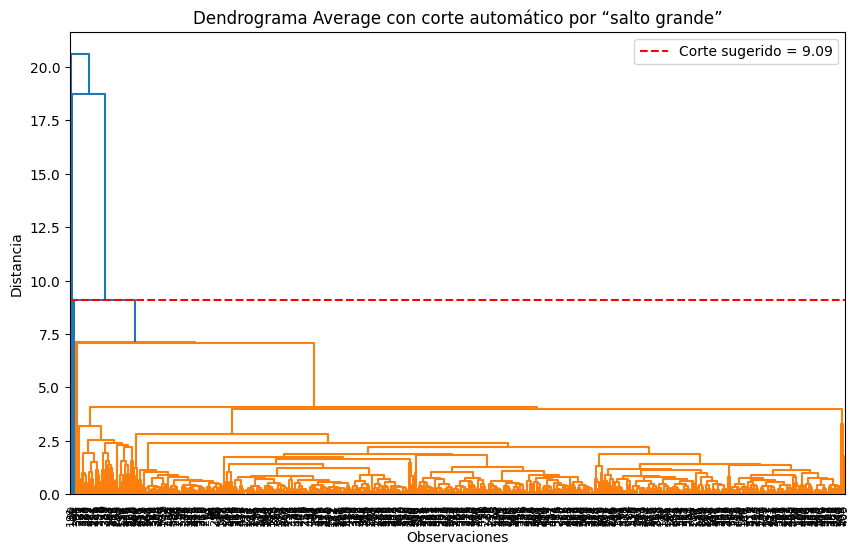

In [21]:
Z = linkage(sample_scaled, method='average')

#Extraemos las distancias (3° columna de Z)
distances = Z[:, 2]

# Identificamos el salto grande
# Diferencia entre distancias consecutivas
diff = np.diff(distances)

# índice del salto más grande
idx_jump = np.argmax(diff)

# Umbral donde ocurre ese salto
threshold = distances[idx_jump]

print("📌 Umbral de corte recomendado:", threshold)

# Dendrograma 
plt.figure(figsize=(10, 6))
dendrogram(
    Z,
    color_threshold=threshold,  
    leaf_rotation=90,
    leaf_font_size=8
)
plt.axhline(threshold, color='red', linestyle='--', label=f'Corte sugerido = {threshold:.2f}')
plt.legend()
plt.title('Dendrograma Average con corte automático por “salto grande”')
plt.xlabel('Observaciones')
plt.ylabel('Distancia')
plt.show()